# MiniGPT — a GPT language model built from scratch

**AI Engineering · Assignment 1 — Transformer & GPT from scratch**

A decoder-only Transformer (GPT) written from first principles in PyTorch — scaled dot-product attention,
multi-head split/merge, sinusoidal positional encoding, pre-norm Transformer blocks, causal masking, training loop
and sampling — trained on **Tiny Shakespeare** (character level). No pretrained weights and no `transformers` /
`nn.Transformer` / `nn.MultiheadAttention` classes are used.

| | |
|---|---|
| Model | 4.77 M parameters · 6 layers · 4 heads · d_model 256 · context 256 · 65-character vocabulary |
| Validation | loss **1.353** nats/char · perplexity **3.87** · next-character accuracy **60.0 %** (top-5 **87.0 %**) |
| Baselines | trigram table 38.5 % accuracy · most-frequent character 15.2 % |
| Repository | [https://github.com/AbdulRahmanAzam/minigpt-shakespeare](https://github.com/AbdulRahmanAzam/minigpt-shakespeare) |

**How to run:** `Runtime → Run all`. A GPU runtime (`Runtime → Change runtime type → T4 GPU`) is faster, but every
cell also works on CPU. Outputs from a full run are already saved in this notebook, so it can be read without
running it.

**Contents**
1. Setup · 2. Dataset · 3. Unit tests · 4. Architecture checks (hand-calculated attention, causal mask,
multi-head shapes, positional encoding, model summary) · 5. Training pipeline (overfit gate, loss curves) ·
6. **Accuracy and loss** · 7. Text generation · 8. Attention inspection · 9. Ablation study ·
10. Concept experiments · 11. REST API · 12. (Optional) train from scratch · 13. Limitations

## 1. Setup

In [1]:
import os, sys, json
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("minigpt-shakespeare").exists():
        !git clone -q https://github.com/AbdulRahmanAzam/minigpt-shakespeare.git
    %cd minigpt-shakespeare
    !pip install -q -r requirements.txt
elif Path.cwd().name == "notebooks":          # running locally from the repository
    os.chdir("..")

os.environ["PYTHONIOENCODING"] = "utf-8"     # child processes print unicode safely on every OS
PY = f'"{sys.executable}"'                  # python of this kernel, quoted (paths may contain spaces)

import torch
print("working directory:", Path.cwd())
print("python", sys.version.split()[0], "| torch", torch.__version__,
      "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU)")

working directory: C:\Users\azama\VS Code\PROJECTS\01 Academic Projects\AI Eng Assign 1 MiniGPT
python 3.12.14 | torch 2.11.0+cu128 | GPU: NVIDIA GeForce RTX 3050 Laptop GPU


In [2]:
from IPython.display import Image, Markdown, display

def show(path, width=900):
    display(Image(filename=str(path), width=width))

def show_md(path, max_chars=None):
    text = Path(path).read_text(encoding="utf-8")
    display(Markdown(text if max_chars is None else text[:max_chars]))

## 2. Dataset — Tiny Shakespeare

Source: [Hugging Face `karpathy/tiny_shakespeare`](https://huggingface.co/datasets/karpathy/tiny_shakespeare)
(1,115,394 characters, 40,000 lines). The HF entry is a loading-script dataset that recent `datasets` versions no
longer run, so `prepare_data.py` downloads the same file, verifies its SHA-256 and applies the identical
**90 / 5 / 5** character split. The tokenizer is character level: 65 symbols, no special tokens.

In [3]:
!{PY} scripts/prepare_data.py
print()
print(Path("data/train.txt").read_text(encoding="utf-8")[:400])

sha256 ok      : 86c4e6aa9db7c042ec79f339dcb96d42b0075e16b8fc2e86bf0ca57e2dc565ed
total chars    : 1,115,394  lines: 40,000
train/val/test : 1,003,854 / 55,770 / 55,770
vocab size     : 65  -> ['\n', ' ', '!', '$', '&', "'", ',', '-', '.', '3', ':', ';', '?', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']
unseen in val/test: []
wrote C:\Users\azama\VS Code\PROJECTS\01 Academic Projects\AI Eng Assign 1 MiniGPT\data/train.txt, val.txt, test.txt, vocab.json, meta.json

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and w

## 3. Unit tests

59 tests: hand-calculated attention values, softmax properties, equality with PyTorch's reference attention,
causal masking (future tokens never change past outputs, gradients never flow from the future), tensor shapes,
parameter count formula, positional encoding values, tokenizer and target shifting, generation, checkpoint reload
in a fresh process, a tiny overfit gate, and the REST API.

In [4]:
!{PY} -m pytest -p no:warnings --color=no

...........................................................              [100%]
59 passed in 7.49s


## 4. Architecture checks

### 4.1 Self-attention by hand (Figure 1)
Three tokens, d_k = d_v = 2. Every step — QKᵀ, scaling by √d_k, row-wise softmax, weighted sum of V, then the same
with a causal mask — is printed and finally checked against our implementation in `src/attention.py`.

HAND-CALCULATED SCALED DOT-PRODUCT ATTENTION  (3 tokens, d_k = d_v = 2)
Q (one query row per token)
  [1.0000, 0.0000]
  [0.0000, 1.0000]
  [1.0000, 1.0000]
K (one key row per token)
  [1.0000, 0.0000]
  [1.0000, 1.0000]
  [0.0000, 1.0000]
V (one value row per token)
  [1.0000, 0.0000]
  [0.0000, 2.0000]
  [1.0000, 1.0000]

Step 1  S = Q K^T     (S[i, j] = q_i . k_j)
  q1.k1 = 1*1 + 0*0 = 1 | q1.k2 = 1*1 + 0*1 = 1 | q1.k3 = 1*0 + 0*1 = 0
  q2.k1 = 0*1 + 1*0 = 0 | q2.k2 = 0*1 + 1*1 = 1 | q2.k3 = 0*0 + 1*1 = 1
  q3.k1 = 1*1 + 1*0 = 1 | q3.k2 = 1*1 + 1*1 = 2 | q3.k3 = 1*0 + 1*1 = 1
  [1.0000, 1.0000, 0.0000]
  [0.0000, 1.0000, 1.0000]
  [1.0000, 2.0000, 1.0000]

Step 2  S / sqrt(d_k) = S / sqrt(2) = S / 1.4142
  [0.7071, 0.7071, 0.0000]
  [0.0000, 0.7071, 0.7071]
  [0.7071, 1.4142, 0.7071]

Step 3  row-wise softmax: w_ij = exp(s_ij) / sum_j exp(s_ij)
  row 1: exp = [2.0281, 2.0281, 1.0000]  sum = 5.0562
  row 2: exp = [1.0000, 2.0281, 2.0281]  sum = 5.0562
  row 3: exp = [2.0281, 4.1133, 

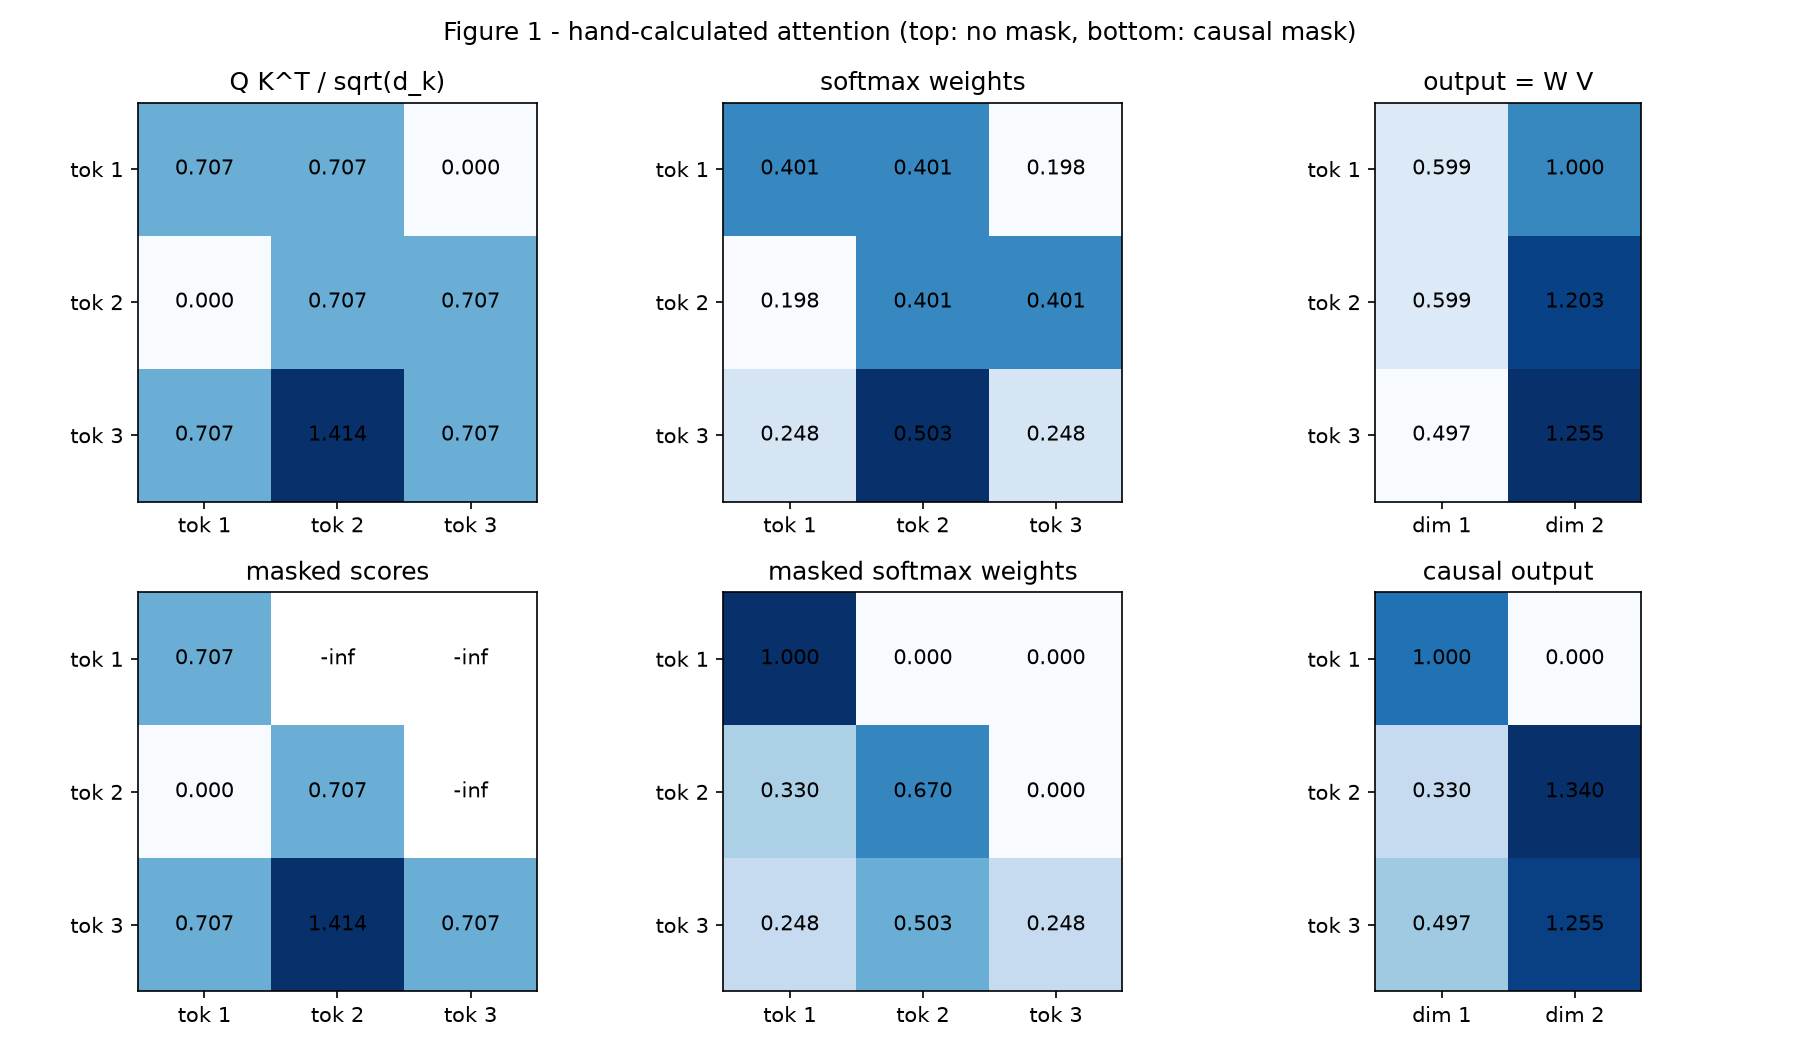

In [5]:
!{PY} -m experiments.hand_attention
show("outputs/figures/fig1_hand_attention.png")

### 4.2 Causal mask vs bidirectional attention (Figure 2)
GPT adds −∞ above the diagonal so position *i* can only attend to positions ≤ *i*; BERT lets every position see
every other position and instead hides input tokens with `[MASK]`.

Causal mask M (added to scores before softmax), tokens = 'R' 'O' 'M' 'E' 'O' ':'
    'R'   0    -inf  -inf  -inf  -inf  -inf
    'O'   0     0    -inf  -inf  -inf  -inf
    'M'   0     0     0    -inf  -inf  -inf
    'E'   0     0     0     0    -inf  -inf
    'O'   0     0     0     0     0    -inf
    ':'   0     0     0     0     0     0  
Row i = query position, column j = key position; -inf above the diagonal blocks the future.

BERT-style bidirectional mask: all zeros (every position sees every other position);
instead of hiding the future, MLM hides ~15% of the *input tokens* with [MASK] and predicts them.

sum of weights above the diagonal: causal = 0.000000, bidirectional = 2.4563
saved outputs\figures\fig2_causal_mask.png


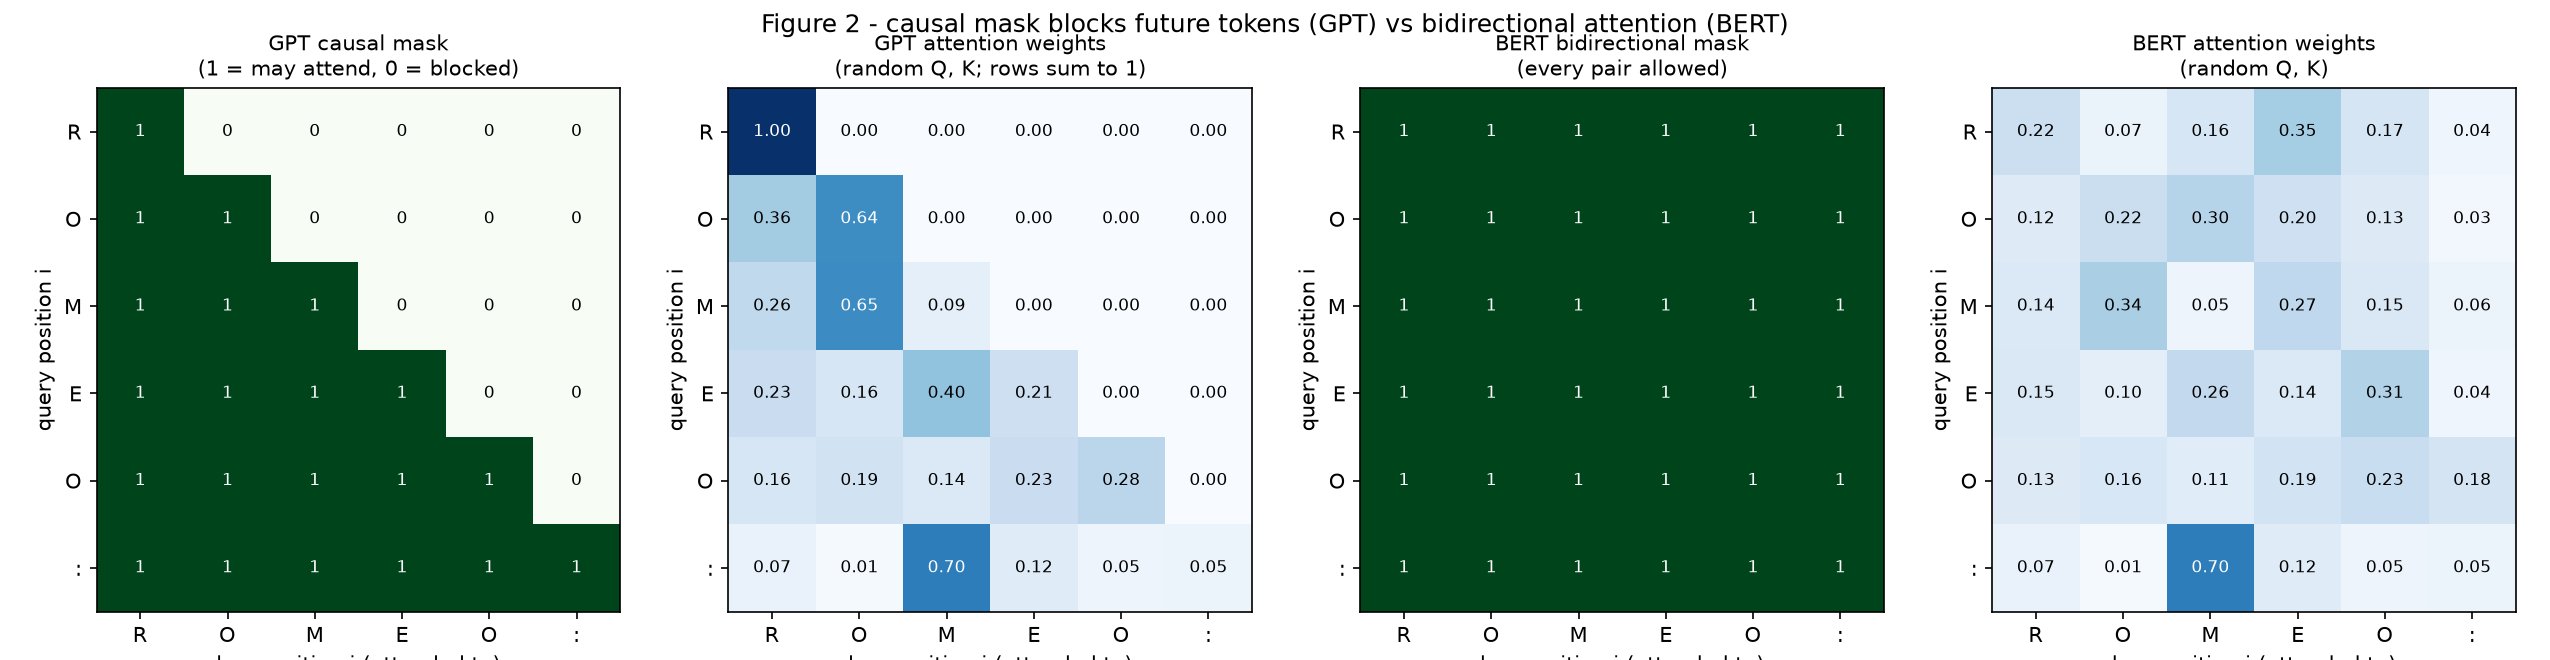

In [6]:
!{PY} -m experiments.mask_visualization
show("outputs/figures/fig2_causal_mask.png", 1100)

### 4.3 Multi-head attention — tensor shapes (Figure 3)
Q, K, V are split into heads, attention runs inside each head, heads are concatenated and projected; the trace
also recomputes every head by hand and checks it equals the module output.

In [7]:
!{PY} -m experiments.shape_trace

MULTI-HEAD ATTENTION SHAPE TRACE  (B=2, T=8, d_model=256, n_heads=4, d_head=64)

[A] full model forward pass (first block traced in detail)
  token ids                   (2, 8)  (B, T)
  token embedding * sqrt(d)   (2, 8, 256)  (B, T, d_model)
  positional encoding         (8, 256)  (T, d_model) broadcast over batch
  input x                     (2, 8, 256)  (B, T, d_model)
  Q = x W_q, K, V             (2, 8, 256)  (B, T, d_model)
  split_heads(Q)              (2, 4, 8, 64)  (B, H, T, d_head)
  scores / weights per head   (2, 4, 8, 8)  (B, H, T, T)
  weights @ V  (per head)     (2, 4, 8, 64)  (B, H, T, d_head)
  merge_heads (concat)        (2, 8, 256)  (B, T, d_model)
  output projection W_o       (2, 8, 256)  (B, T, d_model)
  block output (after FFN)    (2, 8, 256)  (B, T, d_model)
  final LayerNorm -> LM head  (2, 8, 65)  (B, T, vocab_size)
  attention maps returned: 6 layers x (2, 4, 8, 8)

[B] attention inside each head, then concatenation + output projection
  Q, K, V after spli

### 4.4 Sinusoidal positional encoding (Figure 4)
`PE[pos, 2i] = sin(pos / 10000^(2i/d))`, `PE[pos, 2i+1] = cos(pos / 10000^(2i/d))`.

PE . PE at distance 5 across all positions: mean 94.6409, std 1.79e-05 (constant -> encodes relative offset)
||PE[pos]||^2 = d/2 = 128 for every pos: True
saved outputs\figures\fig4_positional_encoding.png


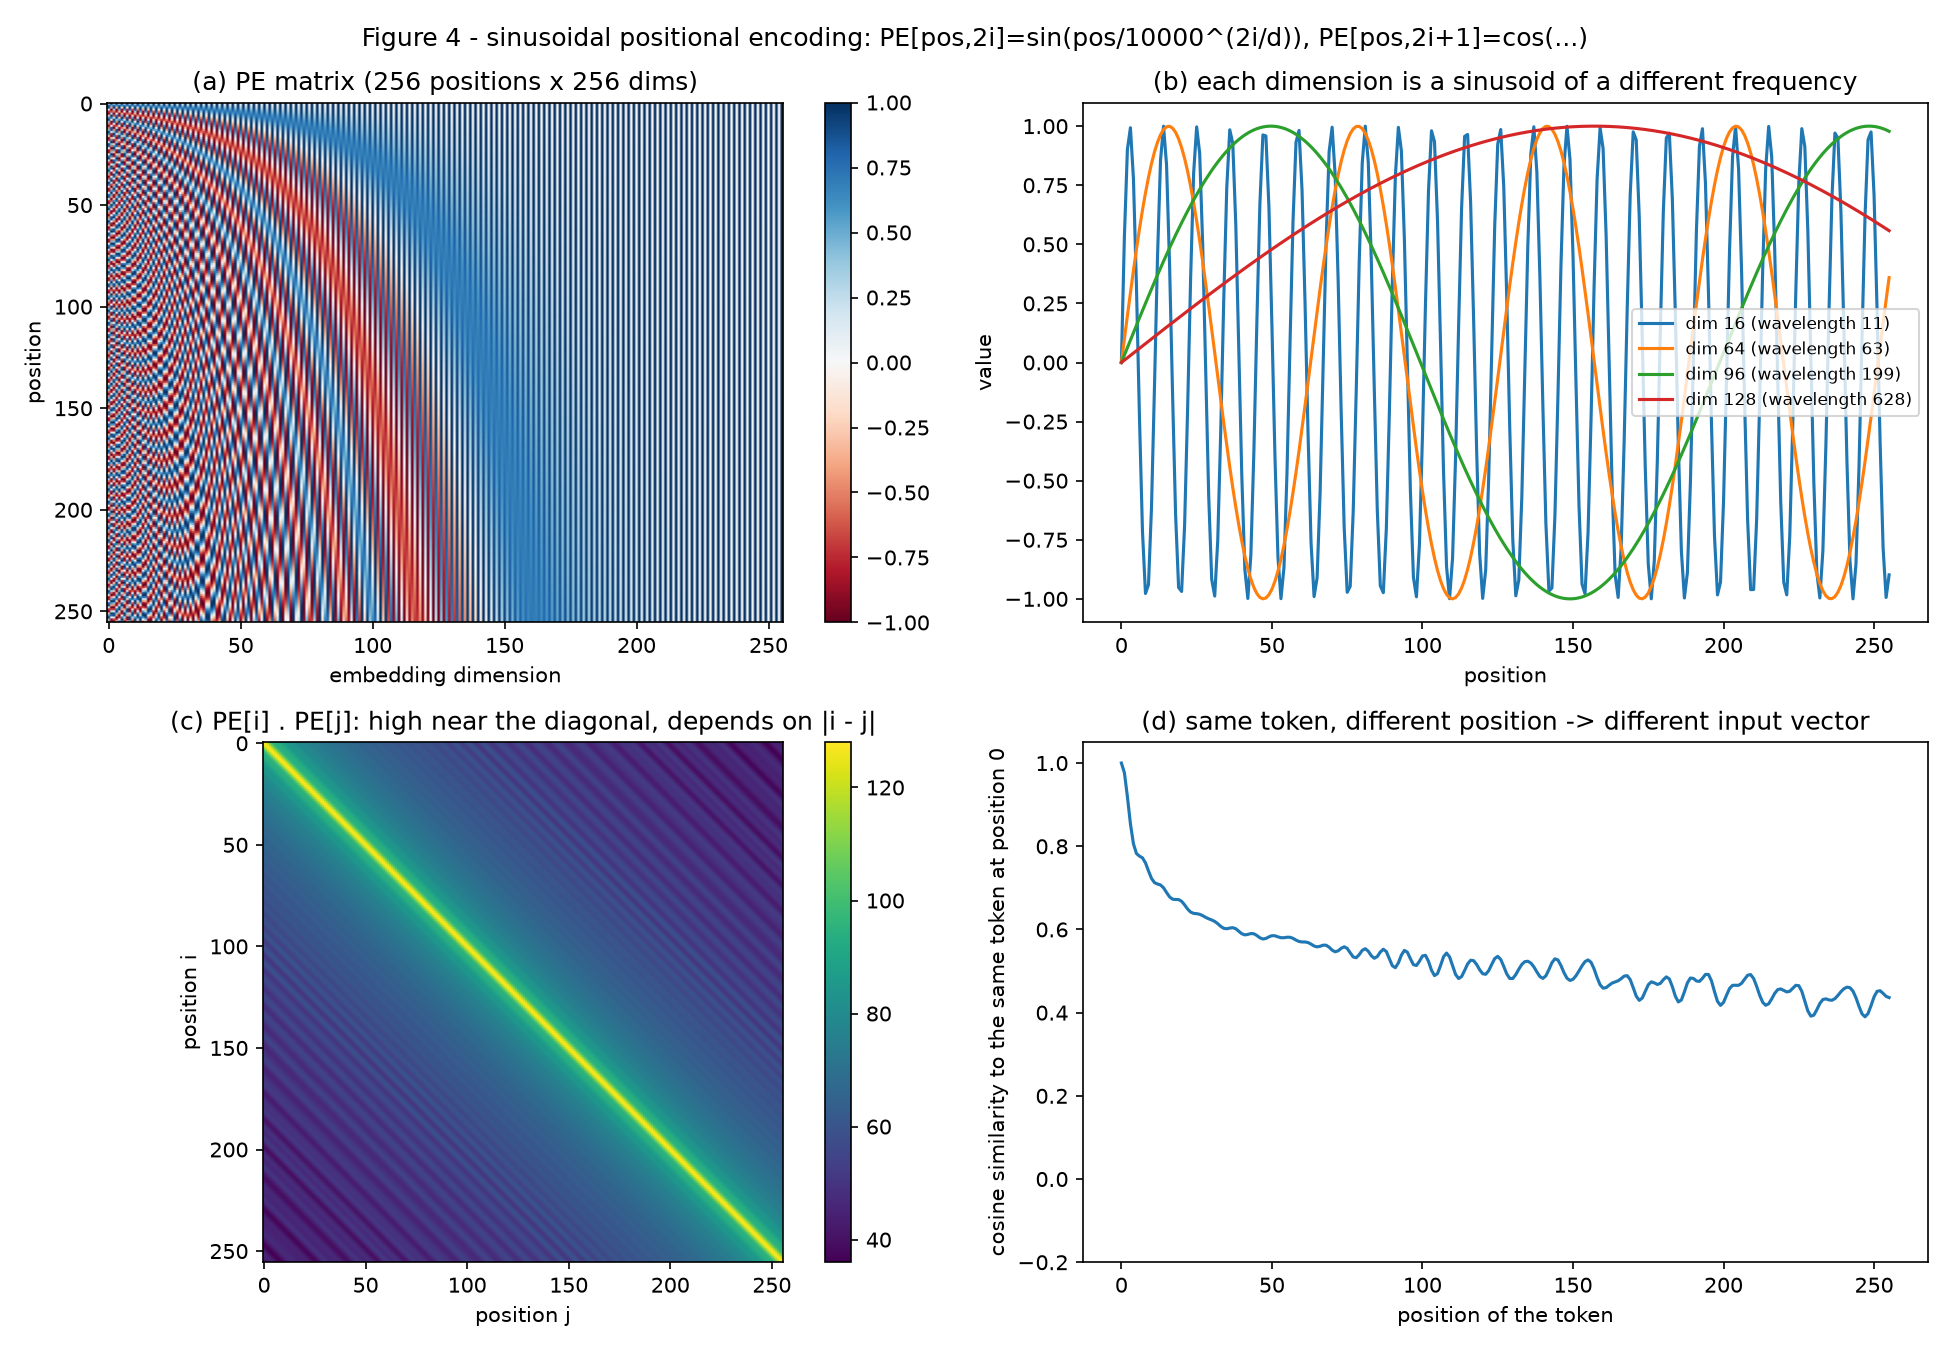

In [8]:
!{PY} -m experiments.positional_encoding_viz
show("outputs/figures/fig4_positional_encoding.png")

### 4.5 The trained model — summary and parameter count (Figure 5)
The trained weights are published as a GitHub Release asset and downloaded here (SHA-256 checked).

In [9]:
CKPT = "checkpoints/minigpt_shakespeare.pt"
if not Path(CKPT).exists():
    !{PY} scripts/download_checkpoint.py
!{PY} -m experiments.model_summary --checkpoint {CKPT}

MiniGPT model summary
  vocab_size       65
  context_length   256
  d_model          256
  n_heads          4
  n_layers         6
  ffn_dim          1024
  dropout          0.2
  pos_encoding     sinusoidal
  tie_weights      False
  attn_impl        manual
  causal           True
  bias             True

  module                            shape                       params
  --------------------------------------------------------------------
  tok_emb.weight                    (65, 256)                   16,640
  blocks.0.ln1.weight               (256,)                         256
  blocks.0.ln1.bias                 (256,)                         256
  blocks.0.attn.q_proj.weight       (256, 256)                  65,536
  blocks.0.attn.q_proj.bias         (256,)                         256
  blocks.0.attn.k_proj.weight       (256, 256)                  65,536
  blocks.0.attn.k_proj.bias         (256,)                         256
  blocks.0.attn.v_proj.weight       (256, 256)      

## 5. Training pipeline

### 5.1 Overfit gate (Milestone 4)
Before long training, the model must memorise a tiny slice of text. Loss should fall from ln 65 ≈ 4.17 (a uniform
guess) to near zero — proof that gradients, the causal mask and the shifted targets are wired correctly.

In [10]:
!{PY} -m src.train --config configs/overfit.yaml

device=cpu (cpu) precision=fp32
params=108,416 (108.4K)  vocab=65  context=32  train_tokens=65  windows/epoch=33
[eval] step      0 | train 4.1979 | val 4.2071 (ppl 67.16)  *best*
step     25 | epoch 196.923 | lr 2.98e-03 | loss 3.0811 | 33k tok/s
step     50 | epoch 393.846 | lr 2.88e-03 | loss 1.1647 | 27k tok/s
step     75 | epoch 590.769 | lr 2.69e-03 | loss 0.3345 | 46k tok/s
step    100 | epoch 787.692 | lr 2.42e-03 | loss 0.0932 | 40k tok/s
[eval] step    100 | train 0.0887 | val 6.7869 (ppl 886.16)
step    125 | epoch 984.615 | lr 2.09e-03 | loss 0.0439 | 27k tok/s
step    150 | epoch 1181.538 | lr 1.74e-03 | loss 0.0338 | 26k tok/s
step    175 | epoch 1378.462 | lr 1.37e-03 | loss 0.0317 | 30k tok/s
step    200 | epoch 1575.385 | lr 1.03e-03 | loss 0.0389 | 41k tok/s
[eval] step    200 | train 0.0260 | val 8.1728 (ppl 3543.21)
step    225 | epoch 1772.308 | lr 7.32e-04 | loss 0.0289 | 43k tok/s
step    250 | epoch 1969.231 | lr 5.01e-04 | loss 0.0266 | 37k tok/s
step    275 | 

### 5.2 How the final model was trained (Figure 6)
AdamW, peak LR 2e-3 chosen by a 6-point sweep, warm-up + cosine decay, dropout 0.2, batch 64 × 256 characters,
3,000 steps (~9 minutes on an RTX 3050 laptop GPU). A 5,000-step run (second figure) shows the model starts to
overfit after ~3,000 steps, which is why training stops there.

parameters         4,772,352
steps              3,000
batch_size         64
tokens_seen        49,152,000
precision          bf16
train_time_s       530.7433
tokens_per_s       92,609.7361
peak_memory_mb     1,835.7866
final_train_loss   1.0652
final_val_loss     1.3549
best_val_loss      1.3531
best_step          2,750
hardware           NVIDIA GeForce RTX 3050 Laptop GPU


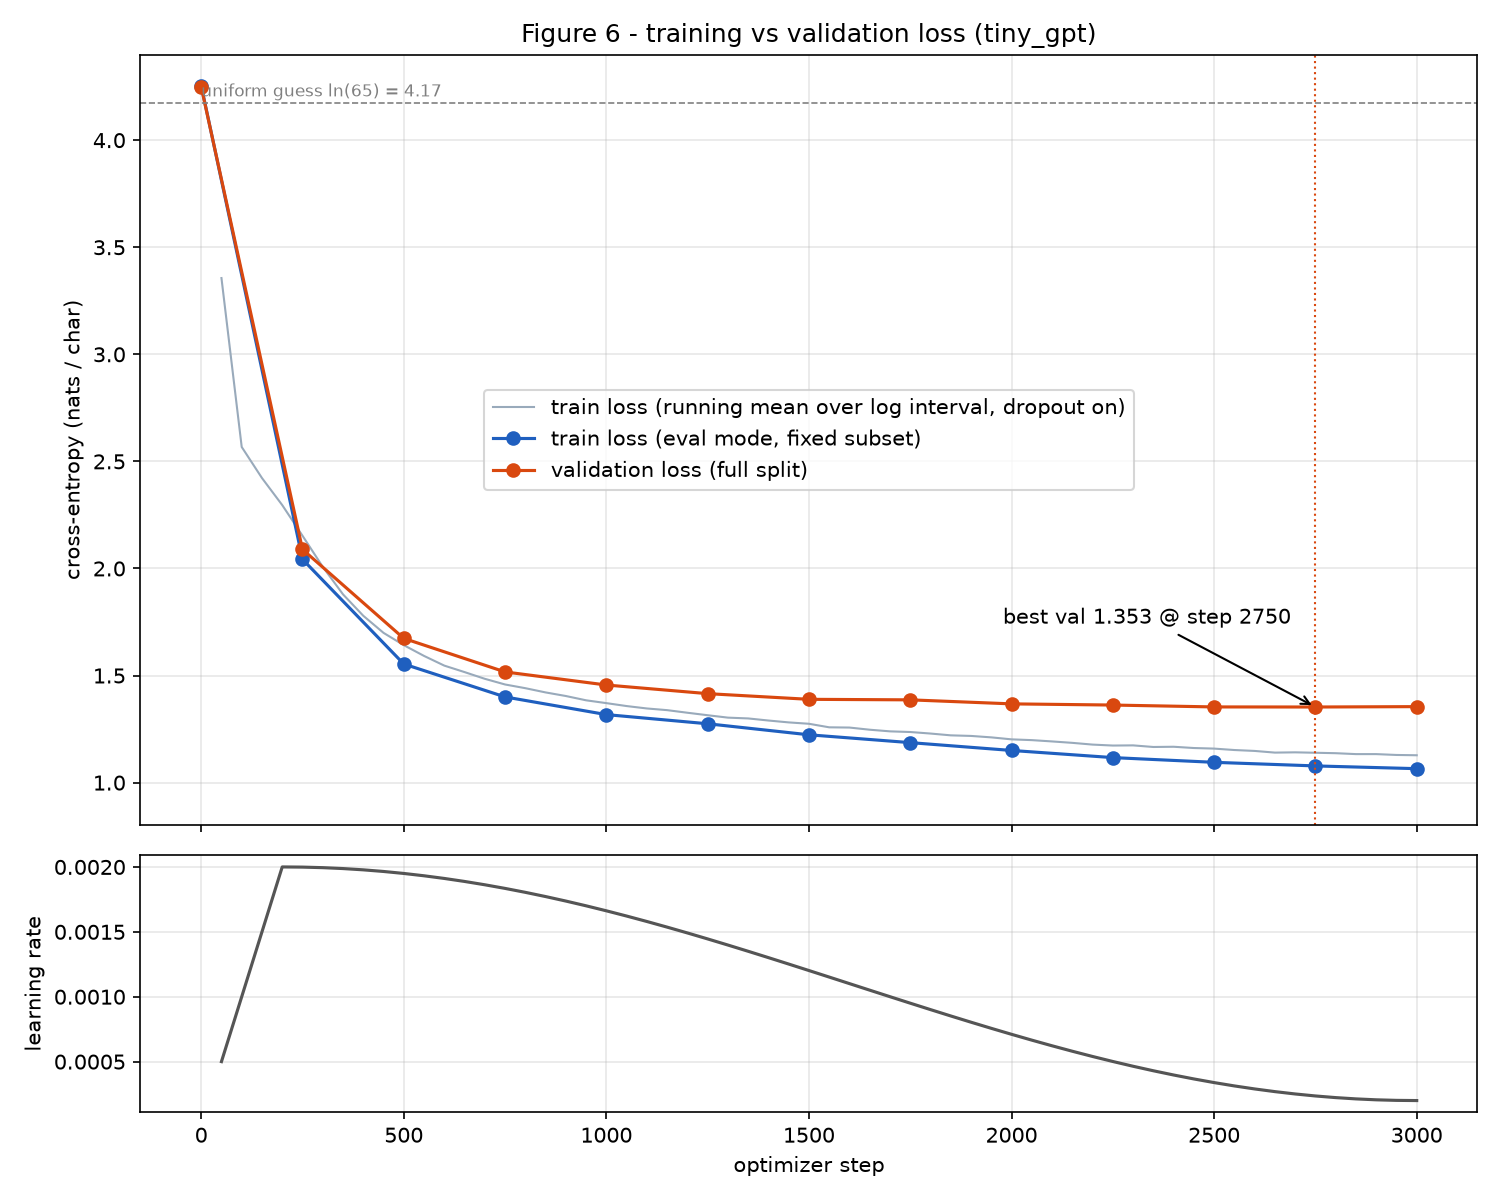

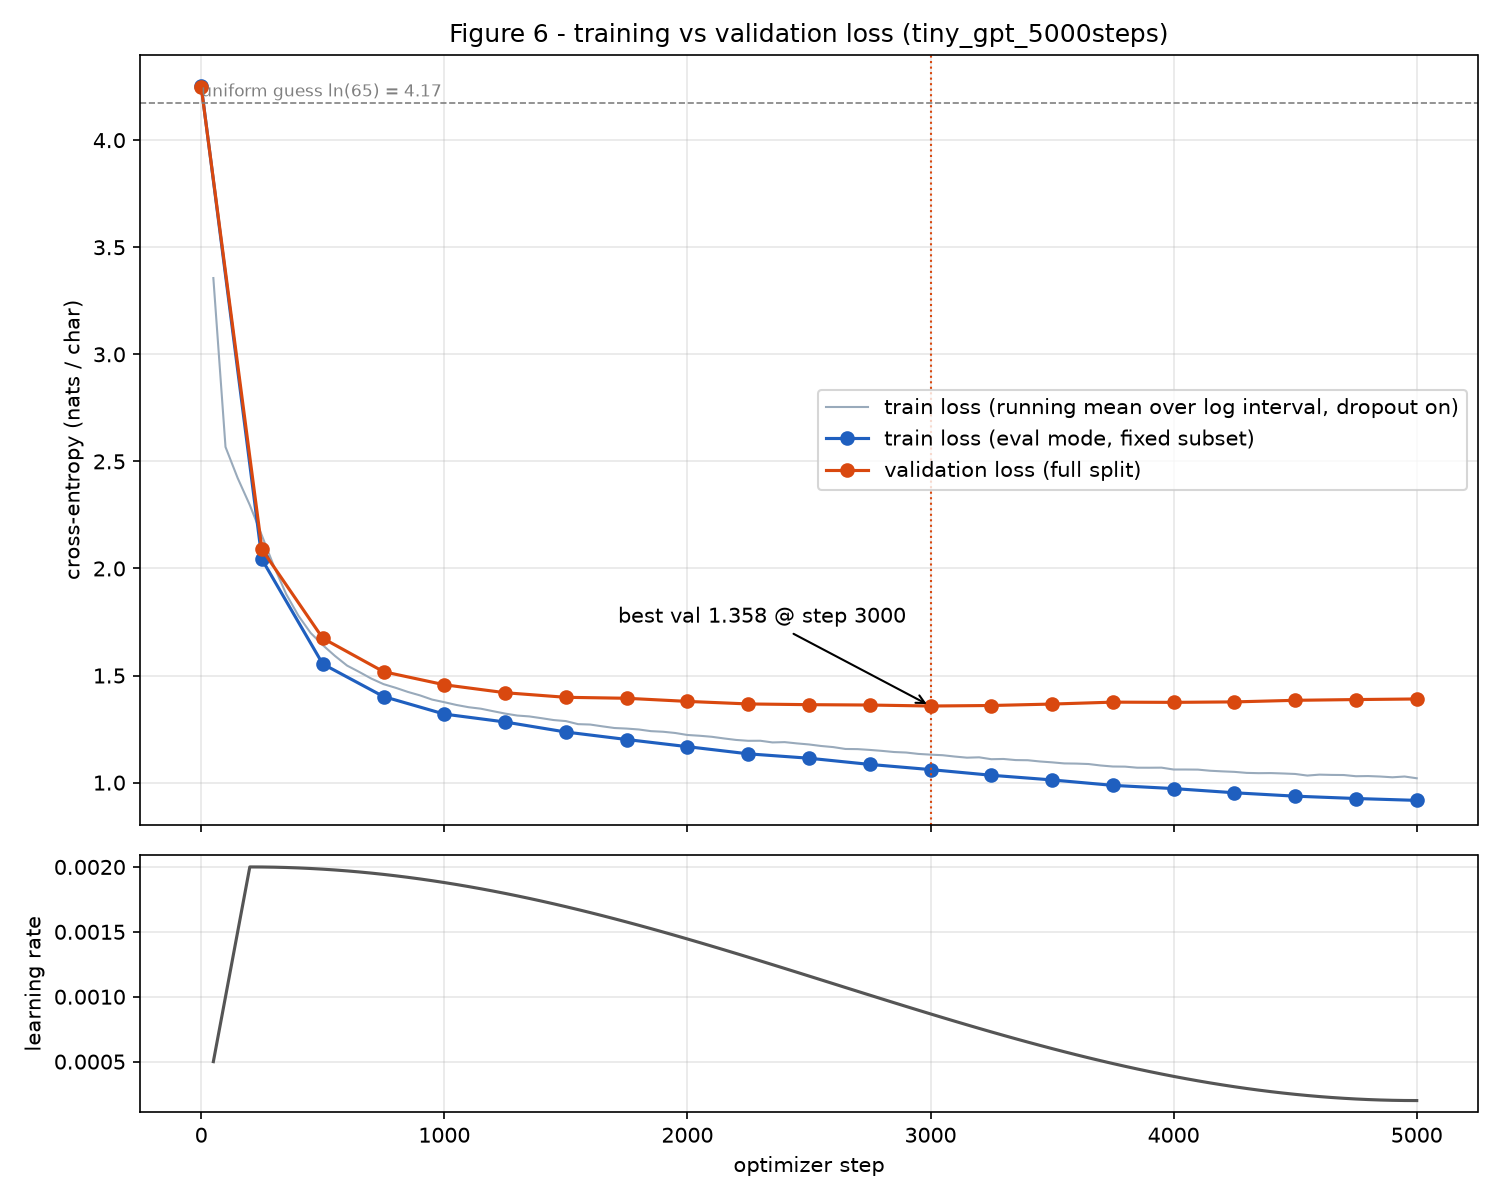

| lr | dropout | steps | train loss | val loss | best val | time (s) |
|---|---|---|---|---|---|---|
| 0.0003 | 0.2 | 1500 | 1.8077 | 1.8894 | 1.8894 | 235.0 |
| 0.0006 | 0.2 | 1500 | 1.523 | 1.6236 | 1.6236 | 243.4 |
| 0.001 | 0.2 | 1500 | 1.3581 | 1.4801 | 1.4801 | 230.6 |
| 0.002 | 0.2 | 1500 | 1.23 | 1.3898 | 1.3898 | 234.5 |
| 0.003 | 0.2 | 1500 | 1.1971 | 1.3726 | 1.3726 | 233.1 |
| 0.004 | 0.2 | 1500 | 1.1883 | 1.3684 | 1.3684 | 231.4 |


In [11]:
summary = json.loads(Path("outputs/logs/tiny_gpt/summary.json").read_text())
for k in ["parameters", "steps", "batch_size", "tokens_seen", "precision", "train_time_s", "tokens_per_s",
          "peak_memory_mb", "final_train_loss", "final_val_loss", "best_val_loss", "best_step"]:
    v = summary[k]
    print(f"{k:<18} {v:,.4f}" if isinstance(v, float) else f"{k:<18} {v:,}" if isinstance(v, int) else f"{k:<18} {v}")
print("hardware          ", summary["hardware"].get("gpu", "cpu"))
show("outputs/figures/fig6_loss_curves.png", 800)
show("outputs/figures/fig6b_overfitting_5000steps.png", 800)
show_md("outputs/tuning/results.md")

## 6. Accuracy and loss of the final model

* **Loss** — mean next-character cross-entropy (nats/char); **perplexity** = e^loss; **bits/char** = loss / ln 2.
* **Accuracy** — how often the model's most likely next character is the true next character (top-1), or is among
  its 5 most likely characters (top-5). Baselines: always predicting the most frequent character, and the best
  bigram / trigram lookup tables built from the training text.
* The test split is reported in two parts: its last 62 % is *The Tempest*, a play that never occurs in training.

This cell also generates the fixed-prompt samples used in the report.

In [12]:
!{PY} -m experiments.evaluate --checkpoint {CKPT}

val   loss 1.3531 | perplexity 3.869 | bits/char 1.952 | next-char accuracy top-1 60.00% top-5 87.05%
test  loss 1.5300 | perplexity 4.618 | bits/char 2.207 | next-char accuracy top-1 56.66% top-5 85.76%
baseline top-1 accuracy on val: most_frequent_char 15.20%, bigram 26.90%, trigram 38.50%
test/seen_plays    21115 chars | loss 1.2609 | perplexity 3.529
test/unseen_play   34655 chars | loss 1.6928 | perplexity 5.435

--- prompt 'ROMEO:' ---
ROMEO:
Far is false; 'tis gone.

MERCUTIO:
Come, you sup your grace is that will conceive
Against me with contrives with the great England.

ROMEO:
That Hermione that we may have proved him within,
Whose canst will we are assured his daughter's mouth?

MERCUTIO:
The case, my lord, the head that send were 

--- prompt 'JULIET:\n' ---
JULIET:
And let us mark me kill my heart.

DUKE VINCENTIO:
So shall see that have thou seen the king.

Provost:
Ay, pity, sir; we must be spoke out at you.

Provost:
Now just, for I have sent me to do them slander.

LUC

In [13]:
ev = json.loads(Path("outputs/eval/final_eval.json").read_text())
bl, ba = ev["baselines"], ev["baseline_accuracy_val"]
rows = [
    ("uniform guess", bl["uniform"], 1 / 65),
    ("most frequent character", bl["unigram"], ba["most_frequent_char"]),
    ("bigram table", bl["bigram"], ba["bigram"]),
    ("trigram table", bl["trigram"], ba["trigram"]),
    ("MiniGPT (validation)", ev["val"]["loss"], ev["val"]["top1_accuracy"]),
    ("MiniGPT (test)", ev["test"]["loss"], ev["test"]["top1_accuracy"]),
]
lines = ["| model | loss (nats/char) | perplexity | top-1 accuracy |", "|---|---|---|---|"]
lines += [f"| {n} | {l:.3f} | {2.718281828 ** l:.2f} | {100 * a:.1f} % |" for n, l, a in rows]
lines += ["", f"MiniGPT top-5 accuracy: validation **{100 * ev['val']['top5_accuracy']:.1f} %**, "
              f"test {100 * ev['test']['top5_accuracy']:.1f} %.",
          f"Test split by play: already-seen play loss **{ev['test_segments']['seen_plays']['loss']:.3f}**, "
          f"unseen *The Tempest* loss **{ev['test_segments']['unseen_play']['loss']:.3f}**."]
display(Markdown("\n".join(lines)))

| model | loss (nats/char) | perplexity | top-1 accuracy |
|---|---|---|---|
| uniform guess | 4.174 | 65.00 | 1.5 % |
| most frequent character | 3.333 | 28.01 | 15.2 % |
| bigram table | 2.474 | 11.87 | 26.9 % |
| trigram table | 2.037 | 7.67 | 38.5 % |
| MiniGPT (validation) | 1.353 | 3.87 | 60.0 % |
| MiniGPT (test) | 1.530 | 4.62 | 56.7 % |

MiniGPT top-5 accuracy: validation **87.0 %**, test 85.8 %.
Test split by play: already-seen play loss **1.261**, unseen *The Tempest* loss **1.693**.

## 7. Text generation

Autoregressive sampling: feed the prompt, take the next-character distribution at the last position, sample
(temperature 0.8), append, repeat — with a sliding 256-character window.

In [14]:
!{PY} -m src.generate --checkpoint {CKPT} --prompt "ROMEO:" --max-new-tokens 300 --seed 42

Prompt: ROMEO:
Generated: ROMEO:
Far is false; 'tis gone.

MERCUTIO:
Come, you sup your grace is that will conceive
Against me with contrives with the great England.

ROMEO:
That Hermione that we may have proved him within,
Whose canst will we are assured his daughter's mouth?

MERCUTIO:
The case, my lord, the head that send were 

model parameters: 4.77M (4,772,352)
architecture: 6 layers, 4 heads, d_model 256, sinusoidal positions, vocab 65 (character-level)
context length: 256
temperature: 0.8
seed: 42
checkpoint: checkpoints\minigpt_shakespeare.pt (step 2750, val loss 1.3531)
device: cuda | 300 new tokens in 2.66s


In [15]:
!{PY} -m src.generate --checkpoint {CKPT} --prompt "To be, or not to be" --max-new-tokens 200 --seed 7
!{PY} -m src.generate --checkpoint {CKPT} --prompt "The future of artificial intelligence" --max-new-tokens 200 --seed 3

Prompt: To be, or not to be
Generated: To be, or not to be my priest honesty.
Tell me, if any more in thing I have drone,
Lest weep not be ashamed in what way is there
For revenge to be his heart that speaks me from thee
To say he shall be in honour of any h

model parameters: 4.77M (4,772,352)
architecture: 6 layers, 4 heads, d_model 256, sinusoidal positions, vocab 65 (character-level)
context length: 256
temperature: 0.8
seed: 7
checkpoint: checkpoints\minigpt_shakespeare.pt (step 2750, val loss 1.3531)
device: cuda | 200 new tokens in 1.62s


Prompt: The future of artificial intelligence
Generated: The future of artificial intelligence, thou
shalt be a month to present thy humour's head
and straight thy household will stab our will?

LEONTES:
Thou canst conceive to take to the fire
Of our charity and minister and straight
By that w

model parameters: 4.77M (4,772,352)
architecture: 6 layers, 4 heads, d_model 256, sinusoidal positions, vocab 65 (character-level)
context length: 256
temperature: 0.8
seed: 3
checkpoint: checkpoints\minigpt_shakespeare.pt (step 2750, val loss 1.3531)
device: cuda | 200 new tokens in 1.64s


**Try your own prompt** — edit the variables and re-run this cell.

In [16]:
from src.checkpoint import load_checkpoint
from src.generate import generate_text

model, tokenizer, _ = load_checkpoint(CKPT, "cuda" if torch.cuda.is_available() else "cpu")

PROMPT = "KING HENRY:"
TEMPERATURE = 0.8      # 0 = greedy (deterministic, tends to repeat); higher = more diverse
MAX_NEW_TOKENS = 300
SEED = 1

r = generate_text(model, tokenizer, PROMPT, MAX_NEW_TOKENS, TEMPERATURE, seed=SEED)
print(r.text)
if r.ignored_chars:
    print("\n(characters outside the 65-character vocabulary were dropped:", r.ignored_chars, ")")

KING HENRY:
They are found to hung their destinies.

WARWICK:
Now Warwick, I am the Duke of Lancaster.

KING RICHARD II:
Why is this, you will swear the field of his sword,
Not hear me, seeing in the king, and benefit sing
To lend my head this enemy, here the queen
Shall the noble Namer to Brittany call thee:



## 8. What the trained model attends to (Figure 7)

Per-head statistics over validation text: early layers contain heads that look almost only at the previous
character (local spelling patterns); the last layers spread attention 30–50 characters back (words, line and
speaker structure). Every weight above the diagonal is exactly zero — the causal mask holds in the trained model.

Per-head attention statistics, averaged over 64 validation windows (context 256, query positions >= 16)
  mean_dist  = expected distance (i - j) to the attended key
  prev       = weight on the immediately preceding character
  self       = weight on the current character
  first      = weight on the first position of the window

layer head  mean_dist   prev   self  first
    0    0       3.11   0.47   0.05   0.00
    0    1       1.71   0.93   0.05   0.00
    0    2       3.68   0.14   0.02   0.00
    0    3       3.18   0.92   0.02   0.00
    1    0      17.62   0.03   0.02   0.01
    1    1       7.29   0.08   0.05   0.00
    1    2       7.24   0.74   0.04   0.00
    1    3       9.32   0.21   0.09   0.00
    2    0       1.45   0.89   0.02   0.00
    2    1       7.03   0.17   0.05   0.00
    2    2       8.84   0.07   0.05   0.00
    2    3       5.54   0.26   0.06   0.00
    3    0       9.56   0.08   0.05   0.00
    3    1       7.28   0.21   0.06   0.00
    3    2       7.12  

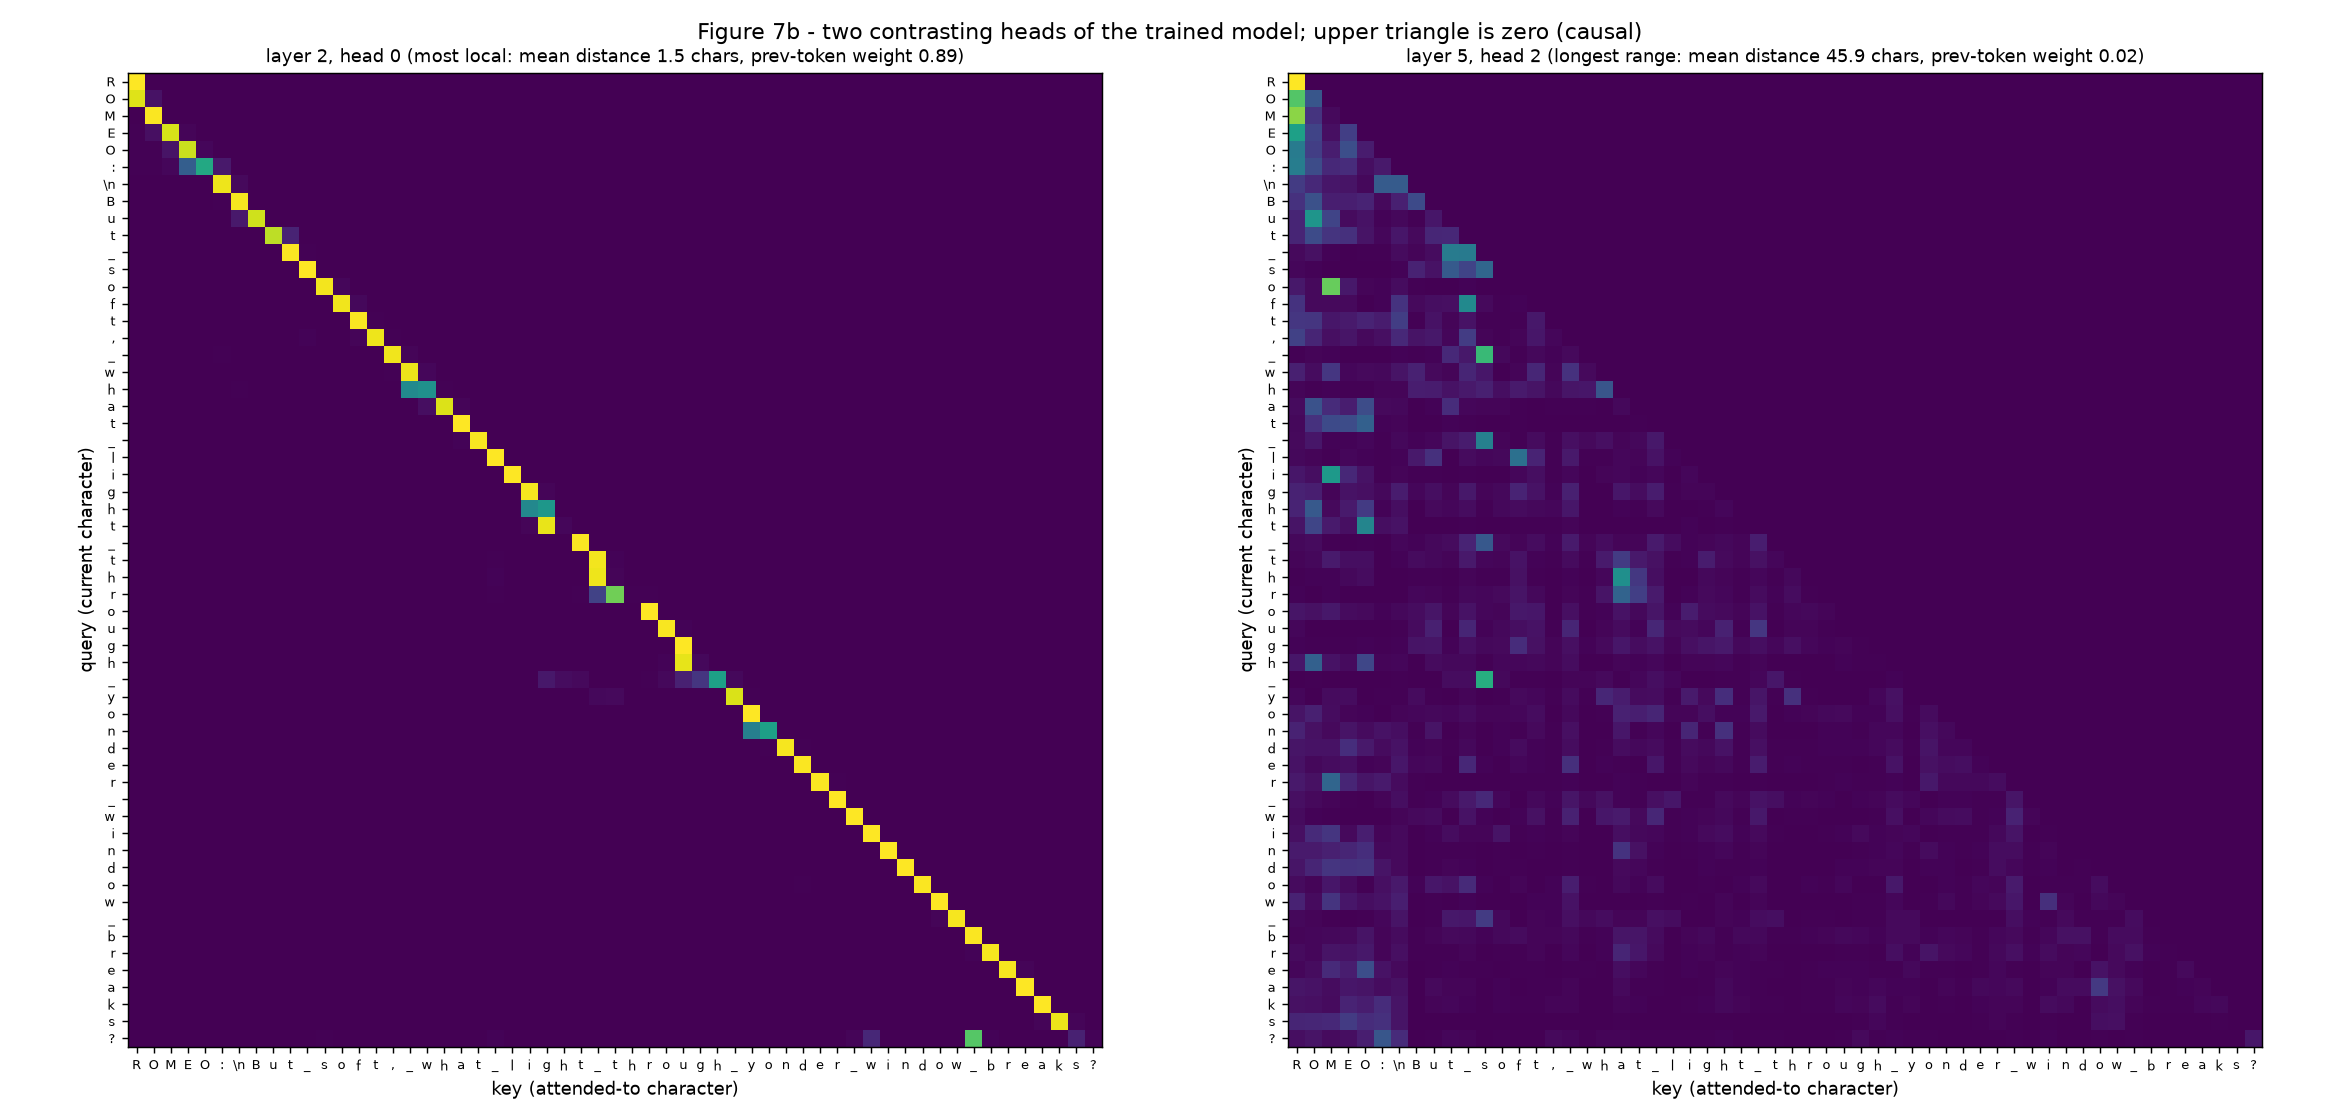

In [17]:
!{PY} -m experiments.attention_visualization --checkpoint {CKPT}
show("outputs/figures/fig7_attention_detail.png", 1100)

## 9. Ablation study (Figure 9)

A small base model (d_model 128, 4 layers, 4 heads, context 128) with **one factor changed at a time**,
3 seeds each, 3,000 steps. Results were produced by `python -m experiments.ablation` (~1 hour on a laptop GPU),
so they are loaded here rather than re-run.

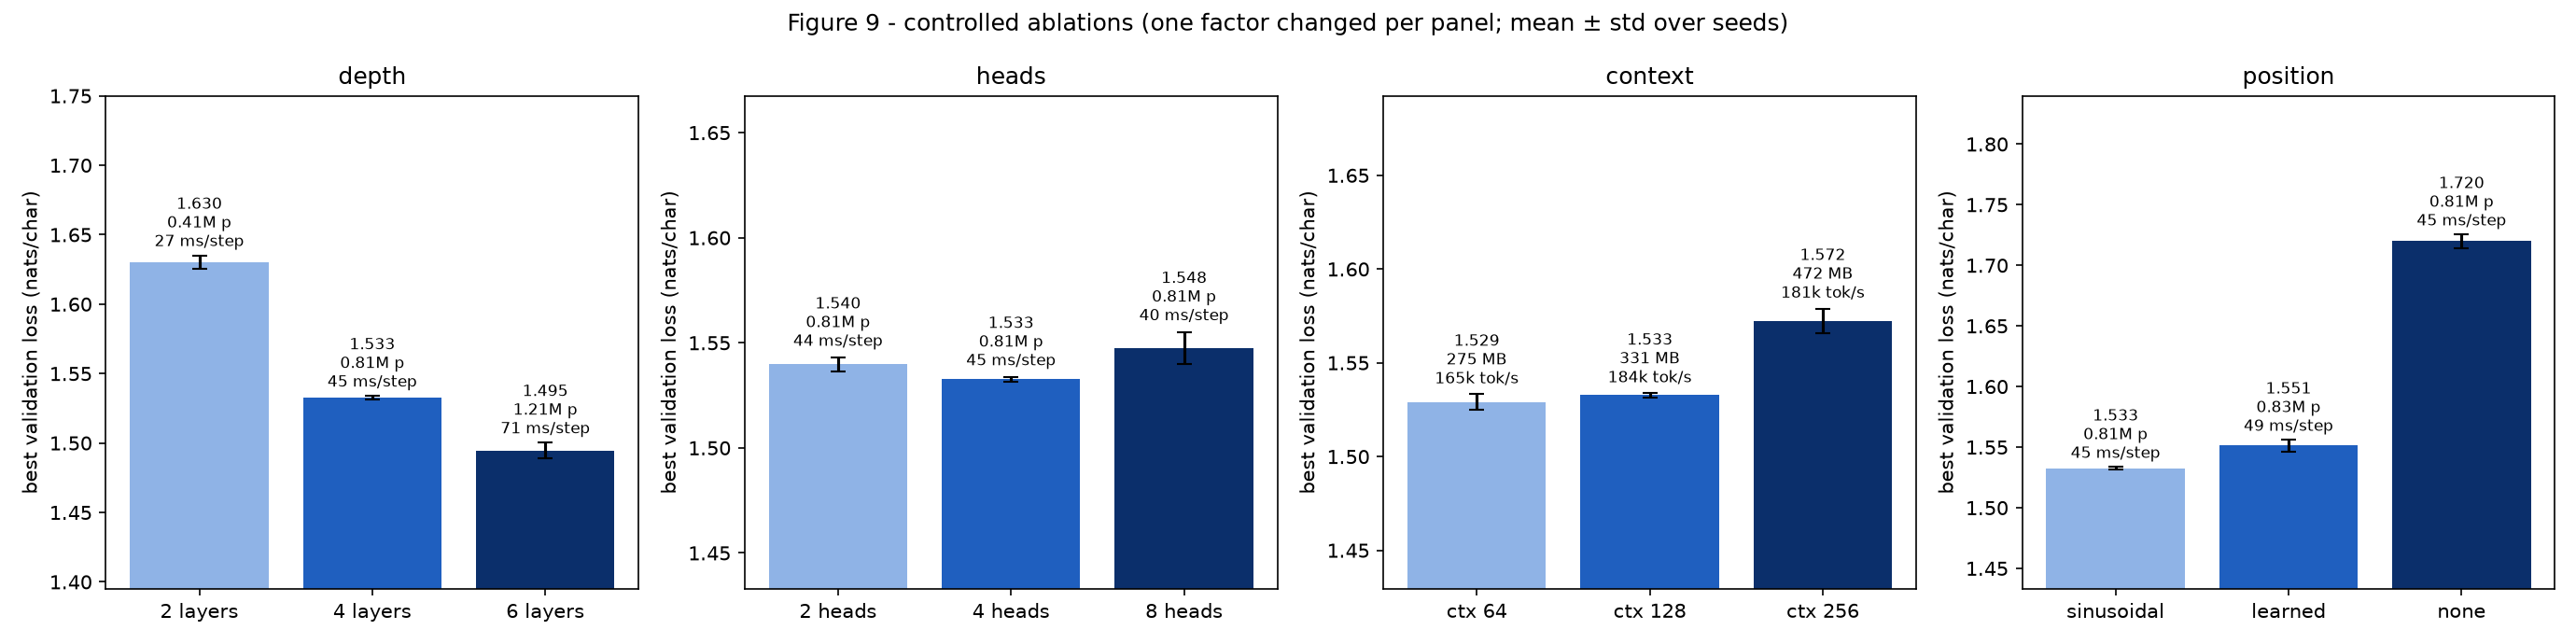

# Ablation results

Base: `configs/ablation_base.yaml` (d_model 128, 4 layers, 4 heads, context 128, sinusoidal, 3000 steps, 8192 tokens/step). Losses and generation metrics are mean ± std over seeds [1337, 1338, 1339] (validation cross-entropy, nats/char). Step time and tokens/s come from the controlled benchmark `experiments/throughput.py` (same random batch, interleaved rounds, median), because in-run timings on a laptop GPU drift with temperature. *In-run time* is the measured training time of the seed-1337 run, which had the GPU to itself (seeds 1338/1339 ran several at a time to save wall-clock - that does not change losses).

## depth

| setting | params | best val loss | final val loss | train loss | step (ms) | tokens/s | peak mem (MB) | in-run time (s) | valid words | distinct-2 | 4-gram rep. |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 2 layers | 413,440 | 1.6301 ± 0.0049 | 1.6301 ± 0.0049 | 1.5299 ± 0.0150 | 27.0 | 303,744 | 185 | 59 | 0.876 | 0.996 | 0.000 |
| 4 layers | 809,984 | 1.5327 ± 0.0011 | 1.5327 ± 0.0011 | 1.4257 ± 0.0122 | 44.5 | 183,932 | 331 | 89 | 0.913 | 0.996 | 0.000 |
| 6 layers | 1,206,528 | 1.4947 ± 0.0056 | 1.4947 ± 0.0056 | 1.3783 ± 0.0121 | 71.4 | 114,739 | 476 | 153 | 0.937 | 0.996 | 0.000 |

## heads

| setting | params | best val loss | final val loss | train loss | step (ms) | tokens/s | peak mem (MB) | in-run time (s) | valid words | distinct-2 | 4-gram rep. |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 2 heads | 809,984 | 1.5398 ± 0.0033 | 1.5398 ± 0.0033 | 1.4348 ± 0.0124 | 44.5 | 184,191 | 275 | 82 | 0.901 | 0.996 | 0.000 |
| 4 heads | 809,984 | 1.5327 ± 0.0011 | 1.5327 ± 0.0011 | 1.4257 ± 0.0122 | 44.5 | 183,932 | 331 | 89 | 0.913 | 0.996 | 0.000 |
| 8 heads | 809,984 | 1.5476 ± 0.0076 | 1.5476 ± 0.0076 | 1.4377 ± 0.0147 | 39.5 | 207,328 | 472 | 144 | 0.905 | 0.998 | 0.000 |

## context

| setting | params | best val loss | final val loss | train loss | step (ms) | tokens/s | peak mem (MB) | in-run time (s) | valid words | distinct-2 | 4-gram rep. |
|---|---|---|---|---|---|---|---|---|---|---|---|
| ctx 64 | 809,984 | 1.5292 ± 0.0041 | 1.5292 ± 0.0041 | 1.4228 ± 0.0185 | 49.7 | 164,958 | 275 | 153 | 0.922 | 0.994 | 0.000 |
| ctx 128 | 809,984 | 1.5327 ± 0.0011 | 1.5327 ± 0.0011 | 1.4257 ± 0.0122 | 44.5 | 183,932 | 331 | 89 | 0.913 | 0.996 | 0.000 |
| ctx 256 | 809,984 | 1.5725 ± 0.0065 | 1.5725 ± 0.0065 | 1.4664 ± 0.0200 | 45.3 | 180,987 | 472 | 221 | 0.886 | 0.994 | 0.000 |

## position

| setting | params | best val loss | final val loss | train loss | step (ms) | tokens/s | peak mem (MB) | in-run time (s) | valid words | distinct-2 | 4-gram rep. |
|---|---|---|---|---|---|---|---|---|---|---|---|
| sinusoidal | 809,984 | 1.5327 ± 0.0011 | 1.5327 ± 0.0011 | 1.4257 ± 0.0122 | 44.5 | 183,932 | 331 | 89 | 0.913 | 0.996 | 0.000 |
| learned | 826,368 | 1.5514 ± 0.0048 | 1.5514 ± 0.0048 | 1.4440 ± 0.0145 | 48.7 | 168,056 | 331 | 116 | 0.911 | 0.993 | 0.000 |
| none | 809,984 | 1.7200 ± 0.0057 | 1.7200 ± 0.0057 | 1.6194 ± 0.0115 | 45.4 | 180,600 | 331 | 115 | 0.783 | 0.996 | 0.000 |



In [18]:
show("outputs/figures/fig9_ablation.png", 1100)
text = Path("outputs/ablations/results.md").read_text(encoding="utf-8")
display(Markdown(text.split("## Sample generations")[0]))

## 10. Concept experiments

* **GPT vs BERT** — the same block trained three ways: causal mask (GPT), no mask with next-token targets
  ("leaky"), and masked-language-modelling (BERT).
* **Why Transformers** — recurrence vs attention speed/memory, and an LSTM language model with the same parameter
  count trained on the same data.
* **Decoding strategies** — greedy vs temperature vs top-k / top-p.

# CLM vs leaky CLM vs MLM

Same architecture (d_model 128, 4 layers, 4 heads, context 128), same data, 1500 steps each.

| model | attention mask | objective val loss | honest next-token loss | hidden-char loss (pos 64) |
|---|---|---|---|---|
| CLM (causal mask) | causal | 1.8057 | 1.6943 | 1.7617 |
| leaky CLM (no mask) | none | 0.0185 | 2.3235 | n/a |
| MLM (bidirectional) | none | 1.9454 | n/a | 1.7796 |

*objective val loss* = each model's own training objective on validation text.  
*honest next-token loss* = predict the character after a 128-char prefix with no future input (the generation setting).  
*hidden-char loss* = predict a character in the middle of a window: MLM sees both sides, CLM only the left side.

**CLM (causal mask)** - left-to-right sample:

```text
ROMEO:
Say her heave and in a should me?

ABOLUNT:
When you hearts was drucking be for ster of with brands,
I will me she of thyse thou had have is a and feaver see arl
Not state the pake is laward not be w
```

**leaky CLM (no mask)** - left-to-right sample:

```text
ROMEO:::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::::W:




W::
I m   i: t aheerencer ser are eake tharthith tharishlararyhail sean
```

**MLM (bidirectional)** - left-to-right sample:

```text
ROMEO:
Sar II moed I am oim ab you y.
Dy ithte ing ine men oug' I
S:
Gourcini seve fot ide is ub ang
A: IOTOI YY INEBNA
D:
ASSH I mth rand aht adil ,dah I
:
GICCILUVLAR
Nakl gaant ith amer dhlang

IT:
AMNIU
```


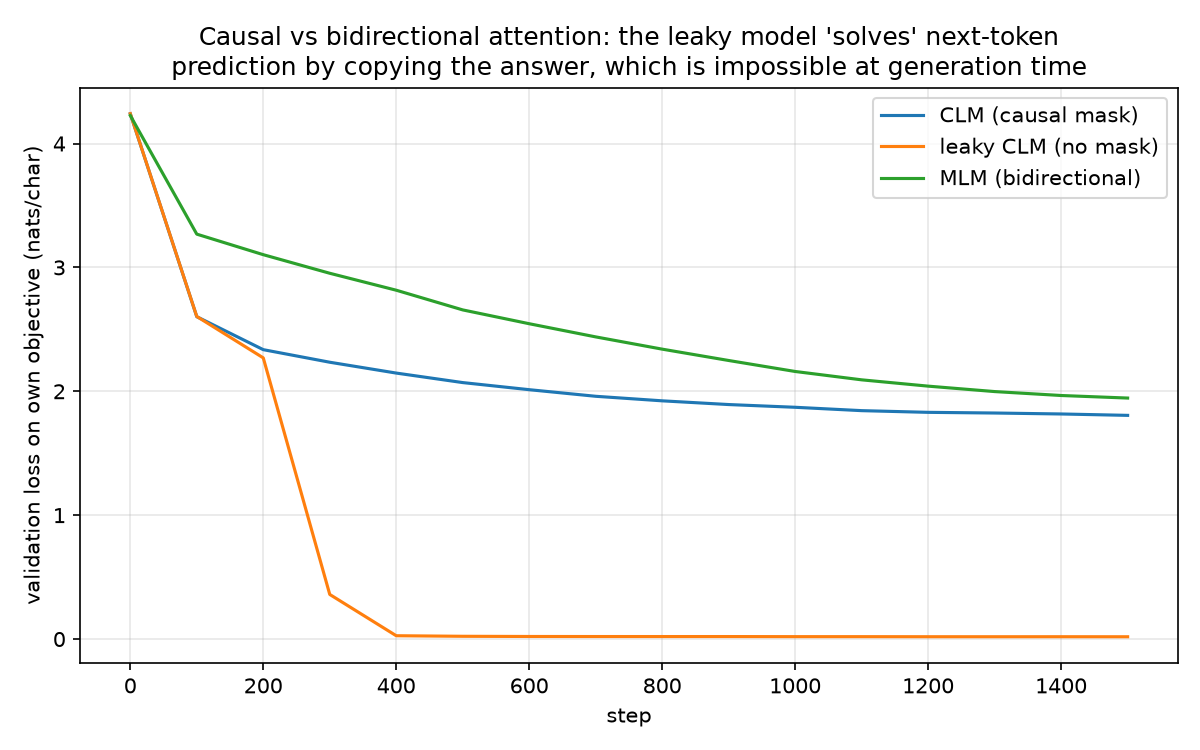

In [19]:
show_md("outputs/mlm_vs_clm/results.md", 1800)
show("outputs/figures/fig2b_mlm_vs_clm.png", 700)

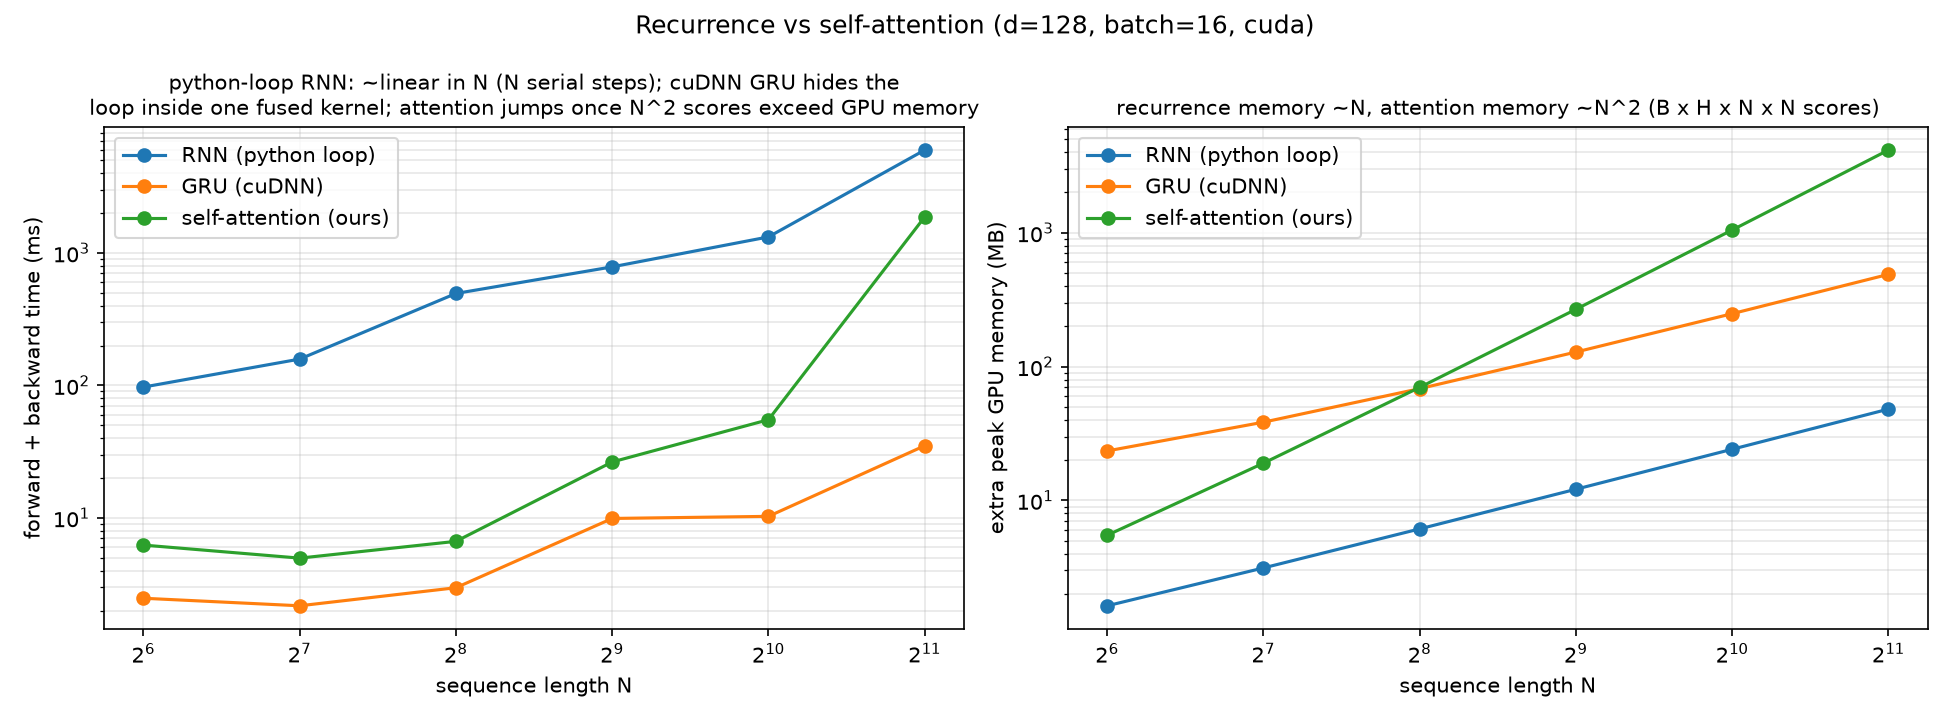

| model | params | best val loss | train time (s) | tokens/s |
|---|---|---|---|---|
| LSTM (2x544) | 4,814,465 | 1.3603 | 281 | 174,871 |
| MiniGPT (6x256) | 4,772,352 | 1.3531 | 531 | 92,610 |


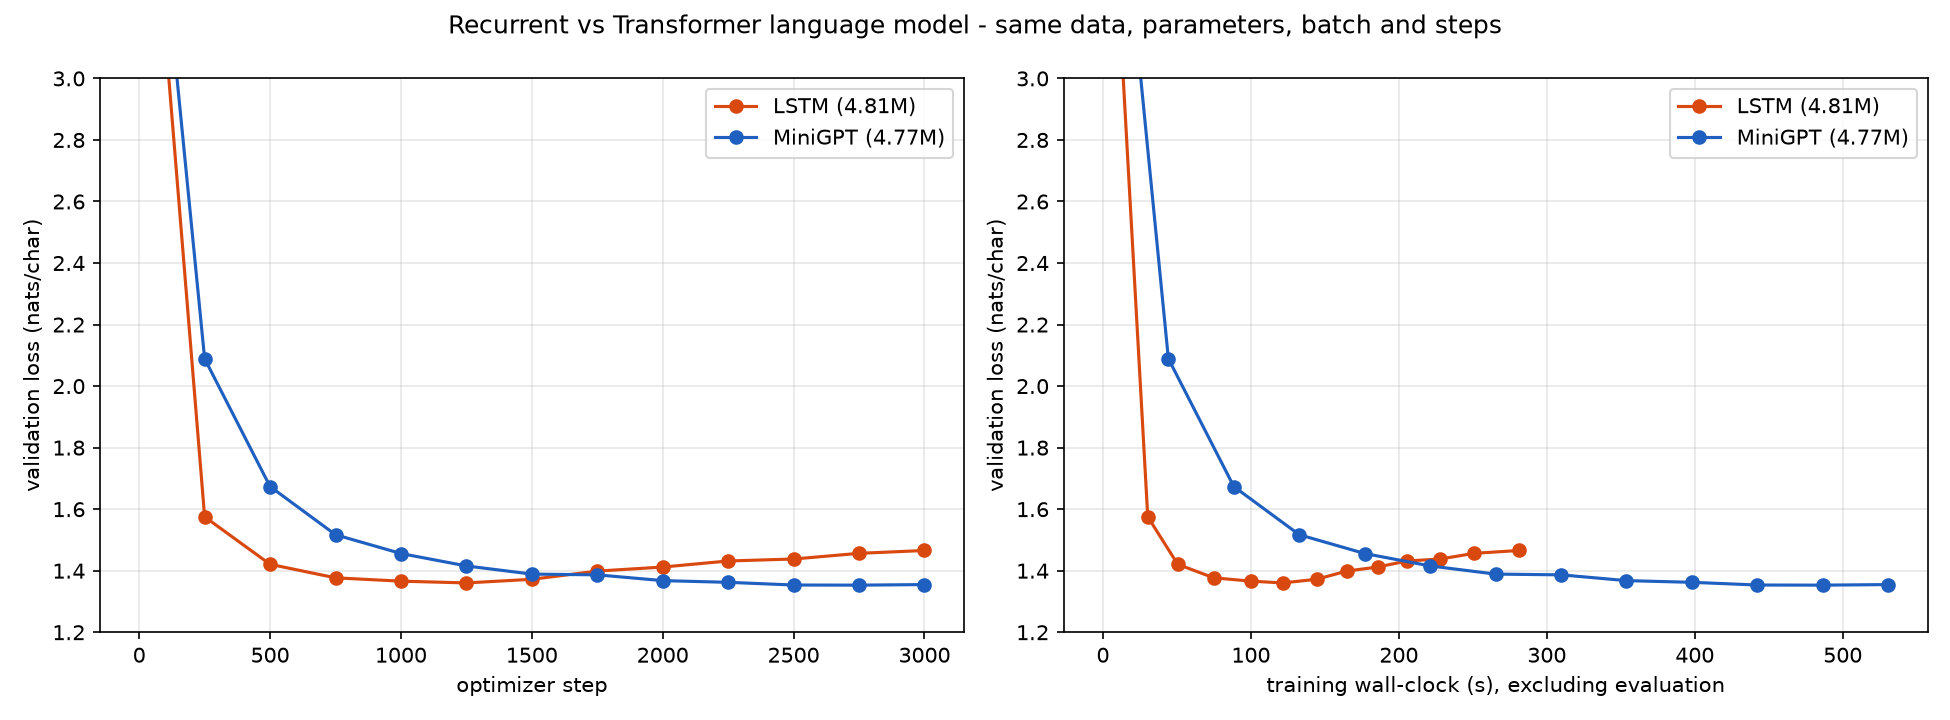

In [20]:
show("outputs/figures/fig0_rnn_vs_attention.png", 1100)
show_md("outputs/lstm_baseline/results.md")
show("outputs/figures/fig0b_lstm_vs_gpt.png", 1000)

In [21]:
text = Path("outputs/decoding/results.md").read_text(encoding="utf-8")
display(Markdown(text.split("## Examples")[0]))

# Decoding strategy comparison

4 prompts x 3 samples x 300 characters (greedy: 1 sample per prompt).

| strategy | valid words | distinct-1 | distinct-2 | 4-gram repetition | model NLL |
|---|---|---|---|---|---|
| greedy (T=0) | 0.986 | 0.338 | 0.488 | 0.350 | 0.529 |
| T=0.5 | 0.996 | 0.700 | 0.963 | 0.000 | 0.775 |
| T=0.8 | 0.979 | 0.806 | 0.989 | 0.000 | 0.886 |
| T=1.0 | 0.950 | 0.856 | 0.993 | 0.000 | 1.043 |
| T=1.3 | 0.897 | 0.905 | 0.999 | 0.000 | 1.374 |
| T=0.8, top-k=10 | 0.972 | 0.782 | 0.988 | 0.000 | 0.893 |
| T=1.0, top-p=0.9 | 0.969 | 0.810 | 0.991 | 0.000 | 0.937 |



## 11. REST API (FastAPI)

The same model is served by `src/api.py` (also deployed on Render). Here we start the server in the background,
call its endpoints, and stop it.

In [22]:
import subprocess, time, urllib.request

server = subprocess.Popen([sys.executable, "-m", "uvicorn", "src.api:app", "--port", "8000"],
                          stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
def get(path):
    return json.loads(urllib.request.urlopen("http://127.0.0.1:8000" + path, timeout=10).read())
def post(path, payload):
    req = urllib.request.Request("http://127.0.0.1:8000" + path, data=json.dumps(payload).encode(),
                                 headers={"Content-Type": "application/json"})
    return json.loads(urllib.request.urlopen(req, timeout=120).read())

for _ in range(120):
    try:
        print("GET /health ->", get("/health")); break
    except OSError:
        time.sleep(1)
info = get("/model-info")
print("GET /model-info ->", info["parameters"], "parameters, val loss", round(info["metrics"]["val_loss"], 4))
out = post("/generate", {"prompt": "JULIET:", "max_new_tokens": 200, "temperature": 0.8, "seed": 1})
print("POST /generate ->")
print(out["text"])
server.terminate()

GET /health -> {'status': 'ok', 'model_loaded': True}
GET /model-info -> 4772352 parameters, val loss 1.3531


POST /generate ->
JULIET:
Call thy son shall leave me to be my shame!

KING RICHARD III:
Norfolk, my lord, and gave me to my part;
And tell me thy countrymen are to the duke:
And I will give my father's life, from hence,
And 


## 12. (Optional) Train the model from scratch

Set `TRAIN = True` to reproduce the final model (~9 min on an RTX 3050; a Colab T4 uses fp16 automatically).
The new checkpoint is written to `checkpoints/tiny_gpt/best.pt`.

In [23]:
TRAIN = False
if TRAIN:
    !{PY} -m src.train --config configs/tiny_gpt.yaml
    !{PY} -m experiments.plot_training --run outputs/logs/tiny_gpt
    !{PY} -m experiments.evaluate --checkpoint checkpoints/tiny_gpt/best.pt
else:
    print("skipped (set TRAIN = True to run)")

skipped (set TRAIN = True to run)


## 13. Known limitations

1. **Data-limited.** ~1 M training characters: beyond ~3,000 steps the model memorises (train 0.92 vs val 1.39 at
   5,000 steps); a 2.2× larger model or more dropout did not improve validation loss.
2. **Domain shift.** *The Tempest* (62 % of the test split) never appears in training — loss 1.69 there vs 1.26 on
   the already-seen play.
3. **Locally fluent, globally incoherent.** Real words and correct play formatting, but no consistent meaning.
4. **Greedy decoding loops**; use temperature ≥ 0.5.
5. **65-character vocabulary** — digits other than 3, quotes, brackets etc. are dropped from prompts.
6. **256-character context**, no KV cache (generation re-processes the window for every character).

Full details, commands and citations: see the repository README.